# Bergmann's rule in Rodentia: statistical investigation

**Research question:** Is environmental temperature negatively associated with body mass among rodent species, as predicted by Bergmann's rule? Does the association vary between rodent families?

The primary analysis uses linear regression of log-transformed species body mass against median environmental temperature. A complementary, exploratory classification analysis investigates whether body mass and ecological variables predict a species' temperature category. The classification task is **not** a direct test of Bergmann's rule.

Dataset: [Global assessment of Bergmann's rule in mammals and birds (Dryad)](https://datadryad.org/dataset/doi:10.5061/dryad.fxpnvx0xq), filtered to Rodentia. Each row represents a **species**, not an individual animal. The Excel workbook `Dataset_S1.xlsx` should be in the notebook's working directory.

The analyses are conducted with Python, pandas, seaborn, statsmodels, and scikit-learn.

## 1. Imports and data preparation

First verify the Python environment, load the Rodentia worksheet, inspect variables and missing values, then construct the log body-mass variable.

In [1]:
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import sklearn

print(sys.version)
print("Everything is working!")

3.15.2 (main, Nov 11 2026, 00:22:41) [MSC v.1951 64 bit (AMD64)]
Everything is working!


In [2]:
# Load the Rodentia dataset
df = pd.read_excel("Dataset_S1.xlsx", sheet_name="Rodentia")

# Display the first five observations
df.head()

,no,Class,Order,Family,Genus,Species,SubGroup,GenusSR,GenusNo,FamilySR,...,medianLat,medianTemp,MigrationTobias1,MigrationTobias2,MigrationDufour,Hibernation,TrophicLevel,HabitatOpenness,ClimateZone,MolecularData
0,907,mammal,Rodentia,Muridae,Rattus,Rattus adustus,eutheria,66,11,726,...,-5.578841,25.315500,NaN,NaN,NaN,NaN,Omnivore,dense,Tropical,NO
1,908,mammal,Rodentia,Muridae,Rattus,Rattus andamanensis,eutheria,66,11,726,...,22.758039,20.733417,NaN,NaN,NaN,NO,Omnivore,dense,NaN,YES
2,909,mammal,Rodentia,Muridae,Rattus,Rattus annandalei,eutheria,66,11,726,...,2.525565,26.799334,NaN,NaN,NaN,NO,Omnivore,dense,Tropical,NO
3,910,mammal,Rodentia,Muridae,Rattus,Rattus arfakienis,eutheria,66,11,726,...,-1.031048,17.389668,NaN,NaN,NaN,NaN,Omnivore,dense,Tropical,NO
4,911,mammal,Rodentia,Muridae,Rattus,Rattus argentiventer,eutheria,66,11,726,...,3.186669,26.692333,NaN,NaN,NaN,NO,Omnivore,open,Tropical,YES


In [3]:
print("Number of species:", len(df))
print("Number of variables:", len(df.columns))

print("\nColumn names:")
print(df.columns.tolist())

Number of species: 2267
Number of variables: 25

Column names:
['no', 'Class', 'Order', 'Family', 'Genus', 'Species', 'SubGroup', 'GenusSR', 'GenusNo', 'FamilySR', 'FamilyNo', 'BodyMass', 'BodyMassInfer', 'BodyMassRe1', 'BodyMassRe2', 'medianLat', 'medianTemp', 'MigrationTobias1', 'MigrationTobias2', 'MigrationDufour', 'Hibernation', 'TrophicLevel', 'HabitatOpenness', 'ClimateZone', 'MolecularData']


In [4]:
columns = [
    "Species",
    "Family",
    "BodyMass",
    "BodyMassInfer",
    "medianTemp",
    "medianLat",
    "ClimateZone"
]

df[columns].head(10)

,Species,Family,BodyMass,BodyMassInfer,medianTemp,medianLat,ClimateZone
0,Rattus adustus,Muridae,158.0,NO,25.315500,-5.578841,Tropical
1,Rattus andamanensis,Muridae,129.0,NO,20.733417,22.758039,NaN
2,Rattus annandalei,Muridae,216.1,YES,26.799334,2.525565,Tropical
3,Rattus arfakienis,Muridae,81.0,YES,17.389668,-1.031048,Tropical
4,Rattus argentiventer,Muridae,133.1,YES,26.692333,3.186669,Tropical
5,Rattus arrogans,Muridae,82.9,YES,15.773334,-3.908816,Tropical
6,Rattus baluensis,Muridae,108.8,NO,23.838750,6.167774,Tropical
7,Rattus blangorum,Muridae,194.8,YES,16.186750,3.889457,Tropical
8,Rattus bontanus,Muridae,239.0,YES,27.193167,-4.971096,Tropical
9,Rattus burrus,Muridae,190.6,YES,27.391407,7.310295,Tropical


In [5]:
# Count missing values in relevant columns
print(df[columns].isna().sum())

# Check that body mass is positive
print("\nInvalid body masses:",
      (df["BodyMass"] <= 0).sum())

# Count inferred measurements
print("\nBody mass provenance:")
print(df["BodyMassInfer"].value_counts())

Species            0
Family             0
BodyMass           0
BodyMassInfer      0
medianTemp         0
medianLat          0
ClimateZone      133
dtype: int64

Invalid body masses: 0

Body mass provenance:
BodyMassInfer
NO     1866
YES     401
Name: count, dtype: int64


### Log-transforming body mass

Species differ greatly in body mass, so we use $\log_{10}(\mathrm{BodyMass\ in\ grams})$ as the response for linear regression. A one-unit difference on this scale represents a tenfold difference in mass. A log transformation reduces the dominance of very large masses, but it does **not** guarantee normally distributed regression errors.

In [6]:
df["LogBodyMass"] = np.log10(df["BodyMass"])

df[["Species", "BodyMass", "LogBodyMass"]].head()

,Species,BodyMass,LogBodyMass
0,Rattus adustus,158.0,2.198657
1,Rattus andamanensis,129.0,2.110590
2,Rattus annandalei,216.1,2.334655
3,Rattus arfakienis,81.0,1.908485
4,Rattus argentiventer,133.1,2.124178


## 2. Descriptive analysis

Describe the distribution and range of body mass and temperature before fitting models. The `medianTemp` variable represents mean annual temperature associated with the median location of a species' range, rather than a temperature measured for an individual animal.

In [7]:
df[["BodyMass", "LogBodyMass", "medianTemp"]].describe()

,BodyMass,LogBodyMass,medianTemp
count,2267.000000,2267.000000,2267.000000
mean,360.375607,1.954179,19.072769
std,1926.783910,0.580633,7.755080
min,3.900000,0.591065,-12.995000
25%,36.000000,1.556303,15.382333
50%,75.400000,1.877371,21.485500
75%,198.000000,2.296665,25.207376
max,62449.600000,4.795530,29.347668


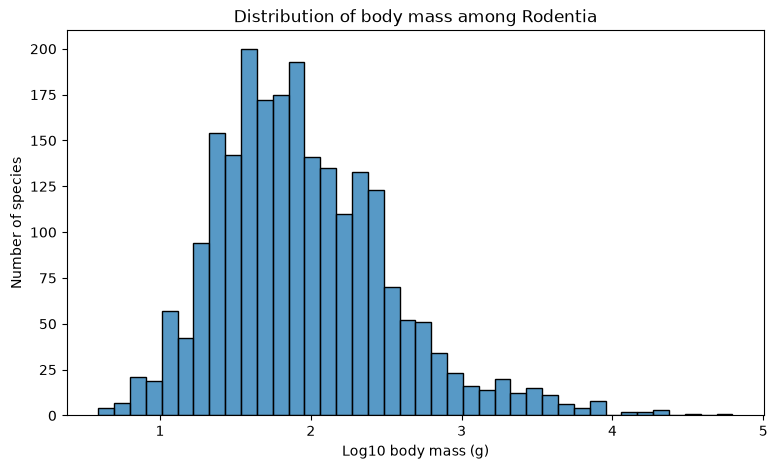

In [8]:
plt.figure(figsize=(9, 5))

sns.histplot(data=df, x="LogBodyMass", bins=40)

plt.xlabel("Log10 body mass (g)")
plt.ylabel("Number of species")
plt.title("Distribution of body mass among Rodentia")

plt.show()

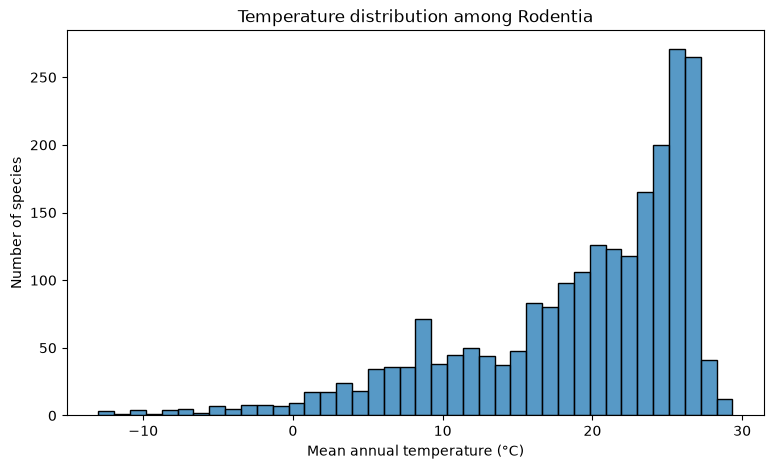

In [9]:
plt.figure(figsize=(9, 5))

sns.histplot(data=df, x="medianTemp", bins=40)

plt.xlabel("Mean annual temperature (°C)")
plt.ylabel("Number of species")
plt.title("Temperature distribution among Rodentia")

plt.show()

### Initial relationship between mass and temperature

The scatter plot shows substantial variation in body mass at most temperatures. There are also considerably more species associated with warm temperatures. An apparent pattern in the largest or smallest observations may be influenced by this unequal number of species across temperature ranges.

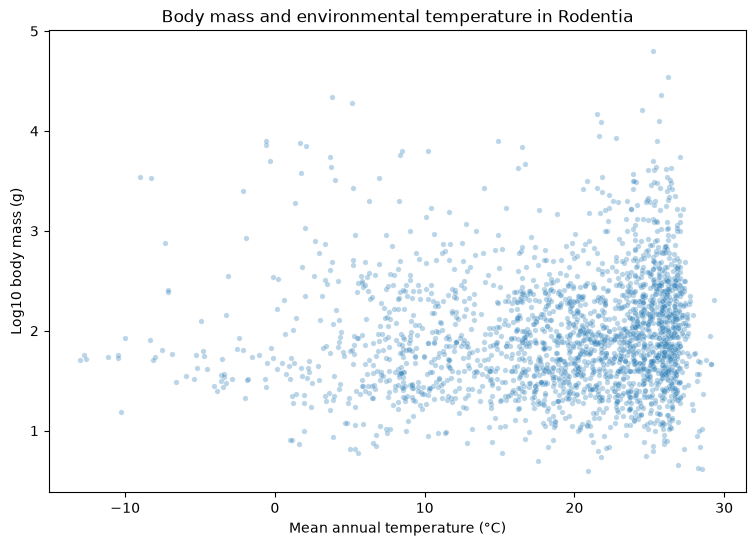

In [10]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="medianTemp",
    y="LogBodyMass",
    alpha=0.3,
    s=15
)

plt.xlabel("Mean annual temperature (°C)")
plt.ylabel("Log10 body mass (g)")
plt.title("Body mass and environmental temperature in Rodentia")

plt.show()

## 3. Linear regression: all rodents

**Predefined hypotheses:** $H_0: \beta_1=0$; Bergmann's rule predicts $H_1: \beta_1<0$, where $\beta_1$ is the slope for `medianTemp` in a model of log body mass. Ordinary least squares estimates the association, not a causal effect. The model summary reports a **two-sided** p-value for a nonzero slope.

In [11]:
import statsmodels.formula.api as smf

model = smf.ols(
    formula="LogBodyMass ~ medianTemp",
    data=df
).fit()

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:            LogBodyMass   R-squared:                       0.005
Model:                            OLS   Adj. R-squared:                  0.004
Method:                 Least Squares   F-statistic:                     10.74
Date:                Sun, 15 Nov 2026   Prob (F-statistic):            0.00106
Time:                        22:07:35   Log-Likelihood:                -1978.4
No. Observations:                2267   AIC:                             3961.
Df Residuals:                    2265   BIC:                             3972.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      1.8561      0.032     57.440      0.0

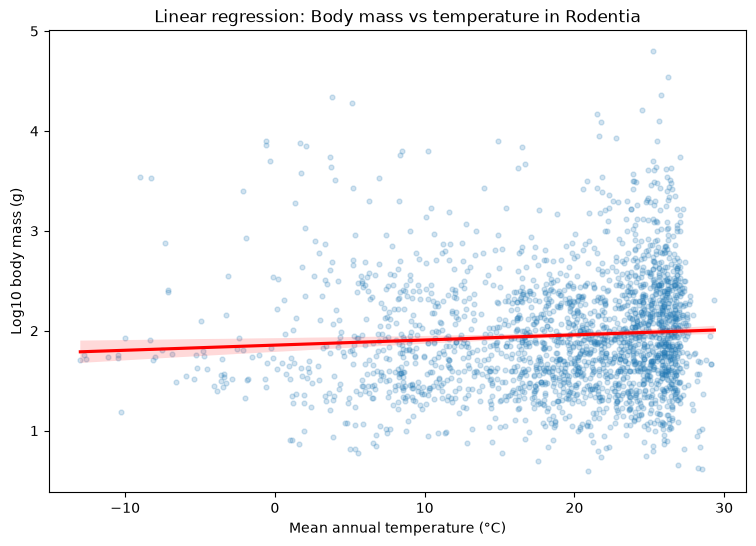

In [12]:
plt.figure(figsize=(9, 6))

sns.regplot(
    data=df,
    x="medianTemp",
    y="LogBodyMass",
    scatter_kws={"alpha": 0.2, "s": 12},
    line_kws={"color": "red"}
)

plt.xlabel("Mean annual temperature (°C)")
plt.ylabel("Log10 body mass (g)")
plt.title("Linear regression: Body mass vs temperature in Rodentia")

plt.show()

### Comparing the three largest families

Muridae, Cricetidae, and Sciuridae were selected for their large sample sizes and temperature coverage, not because of their fitted slopes. Repeating the model within each family tests descriptively whether the order-wide result is consistent across taxonomic groups.

**Observed results:** Rodentia has a very small positive slope ($R^2\approx0.005$). Muridae and Cricetidae also have weak positive slopes; Sciuridae has a negative slope ($R^2\approx0.107$). A negative slope is *consistent with* Bergmann's rule, but does not establish its causal mechanism.

In [13]:
families = ["Muridae", "Cricetidae", "Sciuridae"]

for family in families:
    subset = df[df["Family"] == family]

    family_model = smf.ols(
        "LogBodyMass ~ medianTemp",
        data=subset
    ).fit()

    print(f"\n{family} (n={len(subset)})")
    print("Slope:", round(family_model.params["medianTemp"], 5))
    print("P-value:", round(family_model.pvalues["medianTemp"], 5))
    print("R²:", round(family_model.rsquared, 4))


Muridae (n=726)
Slope: 0.00713
P-value: 0.04337
R²: 0.0056

Cricetidae (n=680)
Slope: 0.0029
P-value: 0.04488
R²: 0.0059

Sciuridae (n=280)
Slope: -0.01861
P-value: 0.0
R²: 0.1066


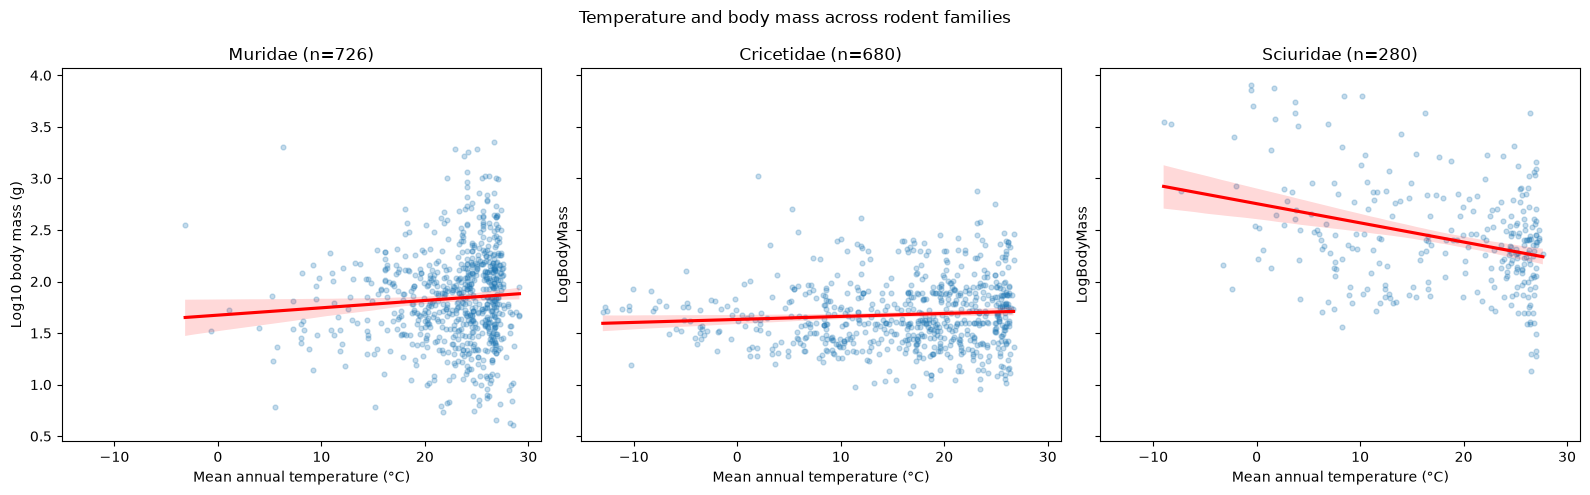

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharex=True, sharey=True)

for ax, family in zip(axes, families):
    subset = df[df["Family"] == family]

    sns.regplot(
        data=subset,
        x="medianTemp",
        y="LogBodyMass",
        ax=ax,
        scatter_kws={"alpha": 0.25, "s": 12},
        line_kws={"color": "red"}
    )

    ax.set_title(f"{family} (n={len(subset)})")
    ax.set_xlabel("Mean annual temperature (°C)")

axes[0].set_ylabel("Log10 body mass (g)")
fig.suptitle("Temperature and body mass across rodent families")
plt.tight_layout()
plt.show()

### Regression diagnostics

A **residual** is observed minus predicted log body mass. Residual plots help assess patterns and changing variance; a QQ-plot helps assess the normality of residuals. The overall model has a narrow range of fitted values because its slope is small.

The QQ-plot shows an unusually long upper tail, and the family residual plots suggest different amounts of scatter across temperatures. These qualify the usual OLS significance tests. Closely related species also cannot automatically be treated as evolutionarily independent.

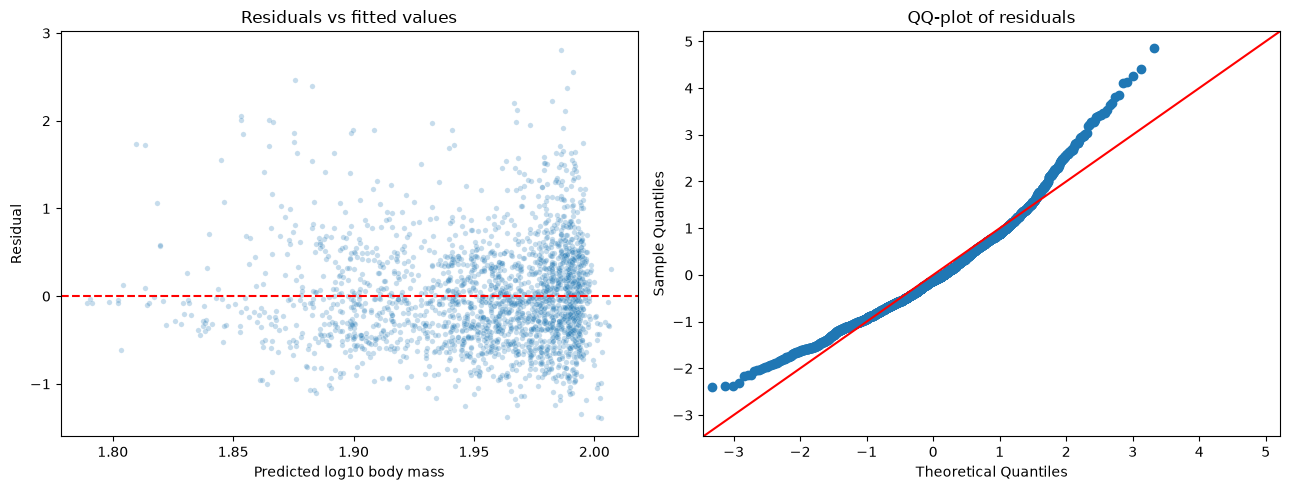

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Residuals against fitted values
sns.scatterplot(
    x=model.fittedvalues,
    y=model.resid,
    alpha=0.25,
    s=15,
    ax=axes[0]
)

axes[0].axhline(0, color="red", linestyle="--")
axes[0].set_xlabel("Predicted log10 body mass")
axes[0].set_ylabel("Residual")
axes[0].set_title("Residuals vs fitted values")

# QQ-plot
sm.qqplot(model.resid, line="45", fit=True, ax=axes[1])
axes[1].set_title("QQ-plot of residuals")

plt.tight_layout()
plt.show()

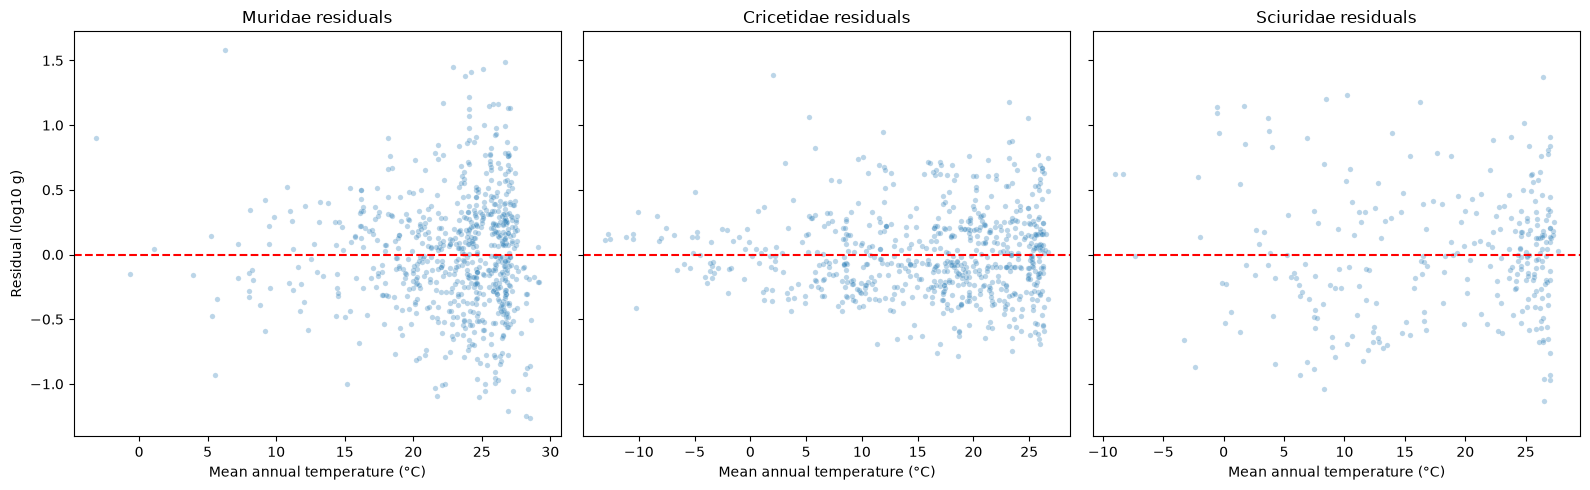

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)

for ax, family in zip(axes, families):
    subset = df[df["Family"] == family]

    family_model = smf.ols(
        "LogBodyMass ~ medianTemp",
        data=subset
    ).fit()

    sns.scatterplot(
        x=subset["medianTemp"],
        y=family_model.resid,
        alpha=0.3,
        s=15,
        ax=ax
    )

    ax.axhline(0, color="red", linestyle="--")
    ax.set_title(f"{family} residuals")
    ax.set_xlabel("Mean annual temperature (°C)")

axes[0].set_ylabel("Residual (log10 g)")
plt.tight_layout()
plt.show()

### Sensitivity to inferred body masses

`BodyMassInfer` distinguishes body-mass records that were inferred from other information. Refit the models using records marked `NO` to assess whether the main slope directions depend on those inferred values. This is a sensitivity check, not a reason to discard inferred records from the primary analysis.

**Result:** The slope directions remain unchanged and their sizes are similar after exclusion. Cricetidae's two-sided p-value rises above 0.05, while its slope remains close to the original estimate.

In [17]:
# Exclude inferred body masses
df_measured = df[df["BodyMassInfer"] == "NO"]

groups = ["Rodentia", "Muridae", "Cricetidae", "Sciuridae"]

for group in groups:
    if group == "Rodentia":
        subset = df_measured
    else:
        subset = df_measured[df_measured["Family"] == group]

    fitted = smf.ols(
        "LogBodyMass ~ medianTemp",
        data=subset
    ).fit()

    print(f"\n{group} (n={len(subset)})")
    print("Slope:", round(fitted.params["medianTemp"], 5))
    print("P-value:", round(fitted.pvalues["medianTemp"], 5))
    print("R²:", round(fitted.rsquared, 4))


Rodentia (n=1866)
Slope: 0.00518
P-value: 0.00451
R²: 0.0043

Muridae (n=561)
Slope: 0.00815
P-value: 0.03401
R²: 0.008

Cricetidae (n=553)
Slope: 0.0031
P-value: 0.07714
R²: 0.0057

Sciuridae (n=263)
Slope: -0.01769
P-value: 0.0
R²: 0.0947


## 4. Exploratory analysis within Sciuridae

Sciuridae shows the clearest negative family-level association, so this secondary analysis examines its genera. The aim is to distinguish **between-genus differences** (for example, large cold-climate genera) from **within-genus trends**. These investigations followed the primary results and should therefore be labeled exploratory.

In [18]:
sciuridae = df[df["Family"] == "Sciuridae"].copy()

# Count species in each genus
genus_counts = sciuridae["Genus"].value_counts()

print(genus_counts)

Genus
Sciurus              28
Tamias               19
Callosciurus         15
Spermophilus         15
Sundasciurus         15
Marmota              14
Urocitellus          12
Paraxerus            11
Funisciurus          10
Petaurista           10
Hylopetes             9
Petinomys             9
Dremomys              6
Heliosciurus          6
Cynomys               5
Funambulus            5
Neotamias             5
Prosciurillus         5
Ammospermophilus      4
Lariscus              4
Microsciurus          4
Ratufa                4
Tamiops               4
Xerospermophilus      4
Xerus                 4
Callospermophilus     3
Exilisciurus          3
Petaurillus           3
Tamiasciurus          3
Aeromys               2
Glaucomys             2
Hyosciurus            2
Ictidomys             2
Iomys                 2
Notocitellus          2
Otospermophilus       2
Protoxerus            2
Pteromys              2
Sciurotamias          2
Aeretes               1
Atlantoxerus          1
Belomys   

In [21]:
sciuridae.groupby("Genus").agg(
    Species=("Species", "count"),
    MeanMass=("BodyMass", "mean"),
    MeanTemp=("medianTemp", "mean"),
    MinTemp=("medianTemp", "min"),
    MaxTemp=("medianTemp", "max")
).sort_values("Species", ascending=False).head(15)

,Species,MeanMass,MeanTemp,MinTemp,MaxTemp
Genus,,,,,
Sciurus,28,599.350000,20.066078,0.212333,26.433666
Tamias,19,75.426316,10.927341,1.375083,16.731167
Callosciurus,15,262.966667,24.246317,18.819834,26.984167
Spermophilus,15,351.206667,5.764428,-0.125833,11.217667
Sundasciurus,15,200.313333,26.571550,24.590166,27.287916
Marmota,14,4964.050000,2.143548,-8.991834,10.225166
Urocitellus,12,382.166667,4.614000,-7.355333,9.676500
Paraxerus,11,269.336364,23.178977,19.412917,26.010250
Funisciurus,10,193.400000,24.303992,20.682667,27.661333


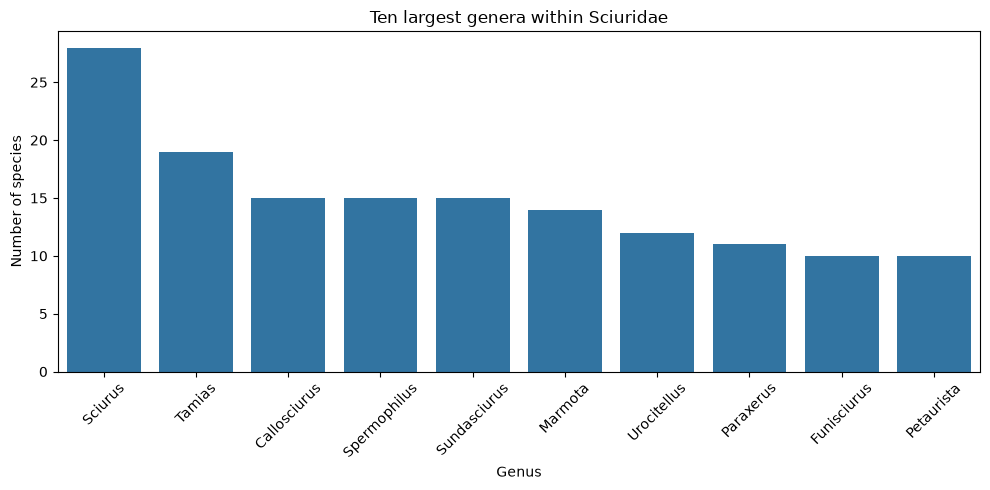

In [22]:
top_genera = genus_counts.head(10)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=top_genera.index,
    y=top_genera.values
)

plt.xlabel("Genus")
plt.ylabel("Number of species")
plt.title("Ten largest genera within Sciuridae")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

### Within-genus regressions

Separate OLS regressions are fitted only for genera with at least ten species. Smaller genera remain in the original family-wide analysis: low genus counts are not evidence that those species are invalid. Interpret these models cautiously because sample sizes and within-genus temperature ranges can be small.

Most of the ten estimated slopes are negative, but only *Urocitellus* has a particularly clear negative association ($R^2\approx0.757$); *Sundasciurus* has a positive association over a narrow temperature range. Multiple exploratory tests mean isolated small p-values should not be overinterpreted.

In [23]:
results = []

for genus in genus_counts[genus_counts >= 10].index:
    subset = sciuridae[sciuridae["Genus"] == genus]

    fitted = smf.ols(
        "LogBodyMass ~ medianTemp",
        data=subset
    ).fit()

    results.append({
        "Genus": genus,
        "Species": len(subset),
        "Slope": fitted.params["medianTemp"],
        "P-value": fitted.pvalues["medianTemp"],
        "R²": fitted.rsquared
    })

genus_results = pd.DataFrame(results)

genus_results.round(4)

,Genus,Species,Slope,P-value,R²
0,Sciurus,28,-0.0018,0.8334,0.0017
1,Tamias,19,-0.0023,0.7727,0.0050
2,Callosciurus,15,-0.0145,0.2576,0.0973
3,Spermophilus,15,-0.0223,0.1925,0.1269
4,Sundasciurus,15,0.2153,0.0102,0.4098
5,Marmota,14,0.0006,0.9469,0.0004
6,Urocitellus,12,-0.0425,0.0002,0.7569
7,Paraxerus,11,-0.0939,0.1408,0.2247
8,Funisciurus,10,-0.0020,0.9497,0.0005
9,Petaurista,10,-0.0052,0.5847,0.0390


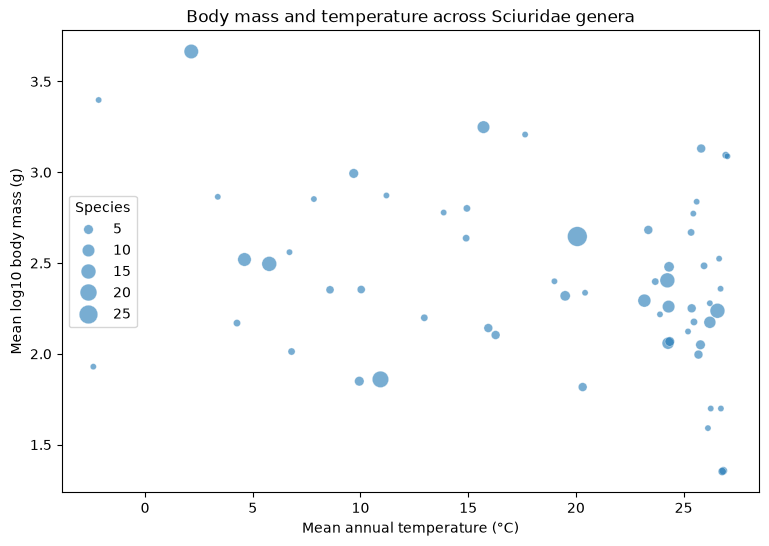

In [24]:
genus_summary = sciuridae.groupby("Genus").agg(
    Species=("Species", "count"),
    MeanLogMass=("LogBodyMass", "mean"),
    MeanTemp=("medianTemp", "mean")
).reset_index()

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=genus_summary,
    x="MeanTemp",
    y="MeanLogMass",
    size="Species",
    sizes=(20, 200),
    alpha=0.6
)

plt.xlabel("Mean annual temperature (°C)")
plt.ylabel("Mean log10 body mass (g)")
plt.title("Body mass and temperature across Sciuridae genera")

plt.show()

### Influence of two genera

Repeat the Sciuridae regression excluding *Marmota*, *Urocitellus*, or both. These are **diagnostic exclusions**, not revised primary samples.

Removing *Marmota* weakens the family-wide relationship considerably ($R^2$ decreases from about 0.107 to 0.020); excluding *Urocitellus* alone changes it little. Excluding both leaves a weak negative slope ($R^2\approx0.012$, two-sided $p\approx0.079$). This suggests the family-level pattern depends substantially on which genera are represented.

In [25]:
excluded_groups = [
    [],
    ["Marmota"],
    ["Urocitellus"],
    ["Marmota", "Urocitellus"]
]

for excluded in excluded_groups:
    subset = sciuridae[
        ~sciuridae["Genus"].isin(excluded)
    ]

    fitted = smf.ols(
        "LogBodyMass ~ medianTemp",
        data=subset
    ).fit()

    label = ", ".join(excluded) if excluded else "All Sciuridae"

    print(f"\nExcluded: {label}")
    print(f"Species: {len(subset)}")
    print(f"Slope: {fitted.params['medianTemp']:.5f}")
    print(f"P-value: {fitted.pvalues['medianTemp']:.5f}")
    print(f"R²: {fitted.rsquared:.4f}")


Excluded: All Sciuridae
Species: 280
Slope: -0.01861
P-value: 0.00000
R²: 0.1066

Excluded: Marmota
Species: 266
Slope: -0.00738
P-value: 0.02087
R²: 0.0201

Excluded: Urocitellus
Species: 268
Slope: -0.01951
P-value: 0.00000
R²: 0.1057

Excluded: Marmota, Urocitellus
Species: 254
Slope: -0.00617
P-value: 0.07934
R²: 0.0122


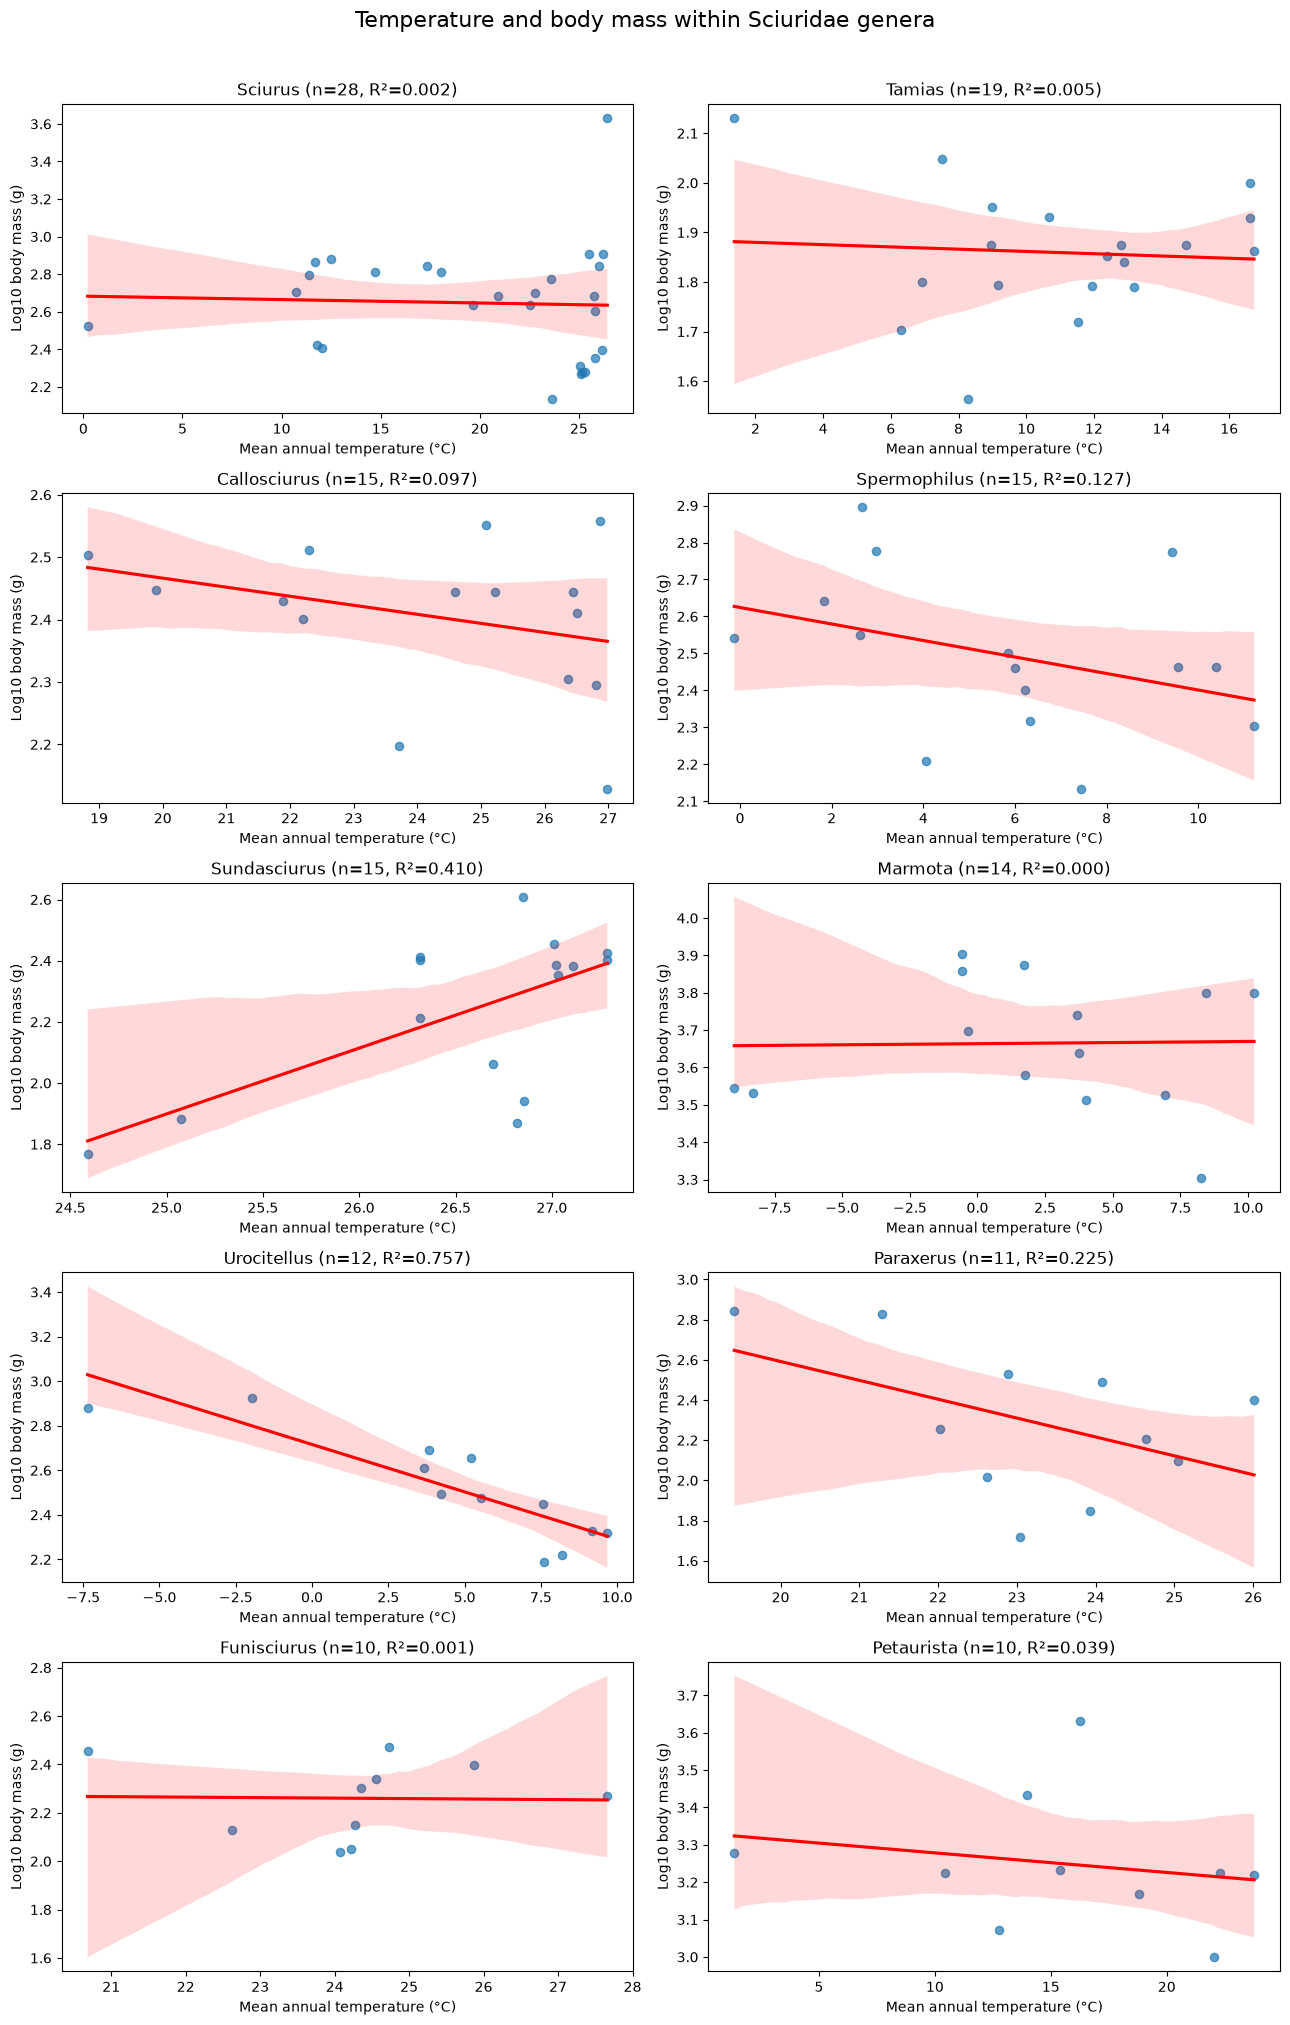

In [26]:
fig, axes = plt.subplots(5, 2, figsize=(13, 20))

for ax, genus in zip(axes.flat, top_genera.index):
    subset = sciuridae[sciuridae["Genus"] == genus]

    fitted = smf.ols(
        "LogBodyMass ~ medianTemp",
        data=subset
    ).fit()

    sns.regplot(
        data=subset,
        x="medianTemp",
        y="LogBodyMass",
        ax=ax,
        scatter_kws={"alpha": 0.7, "s": 35},
        line_kws={"color": "red"}
    )

    ax.set_title(
        f"{genus} (n={len(subset)}, R²={fitted.rsquared:.3f})"
    )

    ax.set_xlabel("Mean annual temperature (°C)")
    ax.set_ylabel("Log10 body mass (g)")

plt.suptitle(
    "Temperature and body mass within Sciuridae genera",
    fontsize=16,
    y=1.01
)

plt.tight_layout()
plt.show()

## 5. Classification: predicting temperature category

The second course topic is **classification**. We ask whether body mass, habitat openness, diet, and family membership can predict whether a rodent species has `medianTemp` below or above 20°C. This complements the regressions but is not itself a test of Bergmann's rule.

We first examine the supplied `ClimateZone` variable. It is defined geographically using latitude and groups together quite different thermal environments. For the classification exercise we instead adopt a **practical, exploratory 20°C cutoff**, partly to avoid severe class imbalance. This is not an established biological boundary. We do not use `medianTemp` as a predictor because it defines our target.

In [27]:
print(df["ClimateZone"].value_counts(dropna=False))

ClimateZone
Tropical     1330
Temperate     804
NaN           133
Name: count, dtype: int64


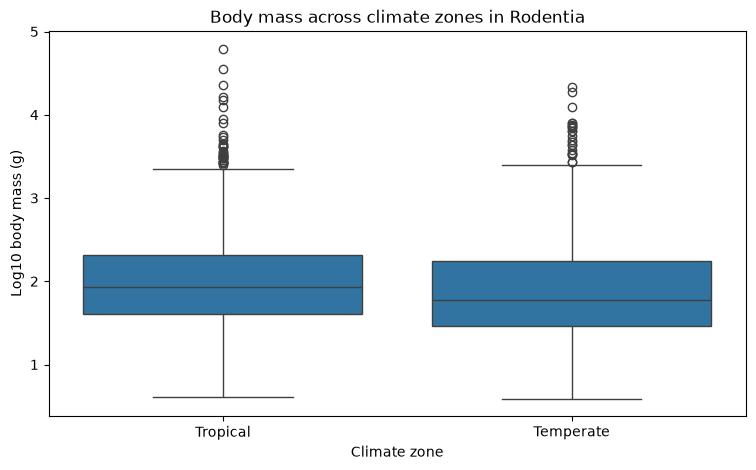

In [28]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="ClimateZone",
    y="LogBodyMass"
)

plt.xlabel("Climate zone")
plt.ylabel("Log10 body mass (g)")
plt.title("Body mass across climate zones in Rodentia")

plt.show()

### Missing values and potential predictors

Examine completeness before comparing classifiers. `HabitatOpenness` has missing values, while `TrophicLevel` and body mass are complete. Hibernation is missing for many species and is therefore not used in the primary classification models. Missing hibernation status must not be interpreted as non-hibernation.

In [29]:
columns = [
    "ClimateZone",
    "LogBodyMass",
    "HabitatOpenness",
    "TrophicLevel",
    "Family"
]

print("Missing values:")
print(df[columns].isna().sum())

print("\nClimate categories:")
print(df["ClimateZone"].value_counts(dropna=False))

print("\nHabitat categories:")
print(df["HabitatOpenness"].value_counts(dropna=False))

print("\nDiet categories:")
print(df["TrophicLevel"].value_counts(dropna=False))

Missing values:
ClimateZone        133
LogBodyMass          0
HabitatOpenness    196
TrophicLevel         0
Family               0
dtype: int64

Climate categories:
ClimateZone
Tropical     1330
Temperate     804
NaN           133
Name: count, dtype: int64

Habitat categories:
HabitatOpenness
open         1056
dense         927
NaN           196
semi-open      85
cave            3
Name: count, dtype: int64

Diet categories:
TrophicLevel
Herbivore    1190
Omnivore      978
Carnivore      99
Name: count, dtype: int64


In [30]:
temperature_bins = [-float("inf"), 0, 10, 20, float("inf")]
temperature_labels = [
    "Below 0°C",
    "0–10°C",
    "10–20°C",
    "Above 20°C"
]

df["TempGroup"] = pd.cut(
    df["medianTemp"],
    bins=temperature_bins,
    labels=temperature_labels
)

print(df["TempGroup"].value_counts().sort_index())

TempGroup
Below 0°C       58
0–10°C         284
10–20°C        626
Above 20°C    1299
Name: count, dtype: int64


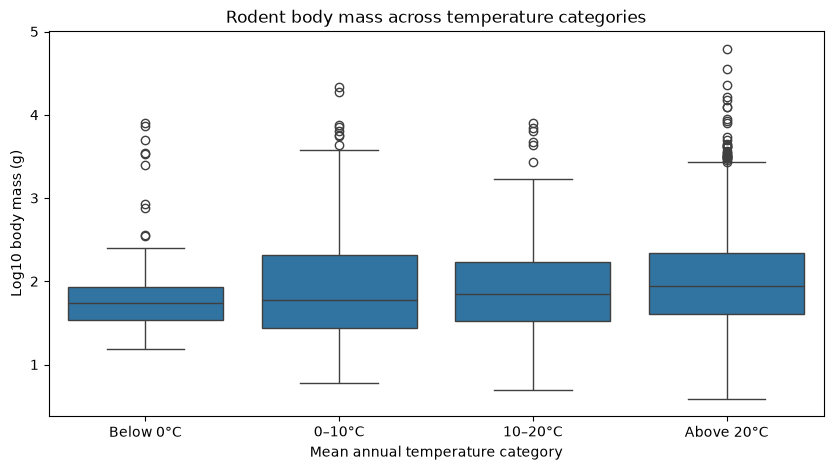

In [31]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x="TempGroup",
    y="LogBodyMass",
    order=temperature_labels
)

plt.xlabel("Mean annual temperature category")
plt.ylabel("Log10 body mass (g)")
plt.title("Rodent body mass across temperature categories")

plt.show()

In [32]:
print(df["Hibernation"].value_counts(dropna=False))

Hibernation
NO     1165
NaN    1043
YES      59
Name: count, dtype: int64


### Exploring the class definitions

The four temperature intervals are used for descriptive plots. The eventual classification is binary: **Cool** below 20°C versus **Warm** at or above 20°C. Diet and habitat cross-tabulations describe associations with these categories, not causation. The class cutoff and additional predictor choices were made during exploratory analysis and should be documented transparently.

In [33]:
# Create a binary temperature category
df["WarmClimate"] = np.where(
    df["medianTemp"] >= 20,
    "Warm",
    "Cool"
)

# Diet distribution within temperature categories
diet_table = pd.crosstab(
    df["TrophicLevel"],
    df["WarmClimate"],
    normalize="columns"
) * 100

print(diet_table.round(1))

# Habitat distribution within temperature categories
habitat_table = pd.crosstab(
    df["HabitatOpenness"],
    df["WarmClimate"],
    normalize="columns"
) * 100

print("\nHabitat distribution:")
print(habitat_table.round(1))

WarmClimate   Cool  Warm
TrophicLevel            
Carnivore      2.4   5.9
Herbivore     59.3  47.4
Omnivore      38.3  46.7

Habitat distribution:
WarmClimate      Cool  Warm
HabitatOpenness            
cave              0.1   0.2
dense            24.2  59.7
open             74.8  33.8
semi-open         0.9   6.4


### Prepare a common dataset and train/test split

For a fair comparison, all five logistic regression models use the same complete-case observations and the same stratified 75% training / 25% test split. Logistic regression predicts the probability of the warm class. Categorical features are one-hot encoded inside a scikit-learn pipeline, with transformations learned from the training set. Family and ecology are used as predictors; neither the response-defining temperature nor median latitude is included.

In [34]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, balanced_accuracy_score, confusion_matrix
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Keep complete observations
classification_df = df[
    ["LogBodyMass", "TrophicLevel", "HabitatOpenness", "Family", "medianTemp"]
].dropna().copy()

# Create binary response variable
classification_df["WarmClimate"] = (
    classification_df["medianTemp"] >= 20
).astype(int)

print("Species available:", len(classification_df))
print(classification_df["WarmClimate"].value_counts())

Species available: 2071
WarmClimate
1    1202
0     869
Name: count, dtype: int64


In [35]:
train_df, test_df = train_test_split(
    classification_df,
    test_size=0.25,
    random_state=42,
    stratify=classification_df["WarmClimate"]
)

### Model evaluation

**Accuracy** is the proportion of correctly classified species. **Balanced accuracy** averages the recall of the cool and warm classes and is useful when class sizes differ. A confusion matrix distinguishes correct and incorrect predictions for each class. A majority-class baseline is necessary because simply predicting the most common class can produce apparently reasonable accuracy.

In [36]:
def evaluate_model(name, predictors):
    categorical = [
        col for col in predictors
        if col != "LogBodyMass"
    ]

    numeric = [
        col for col in predictors
        if col == "LogBodyMass"
    ]

    preprocessing = ColumnTransformer(
        transformers=[
            ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical),
            ("numeric", "passthrough", numeric)
        ]
    )

    classifier = Pipeline([
        ("preprocessing", preprocessing),
        ("model", LogisticRegression(max_iter=2000))
    ])

    classifier.fit(
        train_df[predictors],
        train_df["WarmClimate"]
    )

    predictions = classifier.predict(test_df[predictors])

    accuracy = accuracy_score(
        test_df["WarmClimate"], predictions
    )

    balanced_accuracy = balanced_accuracy_score(
        test_df["WarmClimate"], predictions
    )

    print(f"\n{name}")
    print(f"Accuracy: {accuracy:.3f}")
    print(f"Balanced accuracy: {balanced_accuracy:.3f}")
    print("Confusion matrix:")
    print(confusion_matrix(test_df["WarmClimate"], predictions))

    return classifier

In [37]:
model_a = evaluate_model(
    "Model A: Body mass",
    ["LogBodyMass"]
)

model_b = evaluate_model(
    "Model B: Body mass and ecology",
    ["LogBodyMass", "TrophicLevel", "HabitatOpenness"]
)

model_c = evaluate_model(
    "Model C: Body mass, ecology and family",
    ["LogBodyMass", "TrophicLevel", "HabitatOpenness", "Family"]
)


Model A: Body mass
Accuracy: 0.581
Balanced accuracy: 0.500
Confusion matrix:
[[  0 217]
 [  0 301]]

Model B: Body mass and ecology
Accuracy: 0.705
Balanced accuracy: 0.712
Confusion matrix:
[[164  53]
 [100 201]]

Model C: Body mass, ecology and family
Accuracy: 0.749
Balanced accuracy: 0.733
Confusion matrix:
[[138  79]
 [ 51 250]]


In [38]:
majority_class = train_df["WarmClimate"].mode()[0]

baseline_predictions = np.full(
    len(test_df),
    majority_class
)

print("Baseline accuracy:",
      accuracy_score(test_df["WarmClimate"], baseline_predictions))

print("Baseline balanced accuracy:",
      balanced_accuracy_score(test_df["WarmClimate"], baseline_predictions))

Baseline accuracy: 0.581081081081081
Baseline balanced accuracy: 0.5


### Comparing ecological predictors

The additional models isolate diet and habitat openness while retaining log body mass. The model names indicate their predictor sets, and every model uses the same held-out observations.

**Test-set results:** Body mass alone matches the majority-class baseline (58.1% accuracy; 50.0% balanced accuracy). Adding diet yields 64.7% accuracy; adding habitat yields 68.9%. Combining diet and habitat yields 70.5%, and adding family raises accuracy to 74.9%. These are descriptive test-set differences, not proof that any individual predictor causes climate preference.

In [39]:
model_mass_habitat = evaluate_model(
    "Body mass + habitat",
    ["LogBodyMass", "HabitatOpenness"]
)

model_mass_diet = evaluate_model(
    "Body mass + diet",
    ["LogBodyMass", "TrophicLevel"]
)


Body mass + habitat
Accuracy: 0.689
Balanced accuracy: 0.700
Confusion matrix:
[[166  51]
 [110 191]]

Body mass + diet
Accuracy: 0.647
Balanced accuracy: 0.596
Confusion matrix:
[[ 61 156]
 [ 27 274]]


## 6. Classification figures and interpretation

The bar plot summarizes accuracy and balanced accuracy across models. **Note:** the plotted scores below are entered manually from the observed test output. Recalculate these values if the split, observations, predictors, or models change.

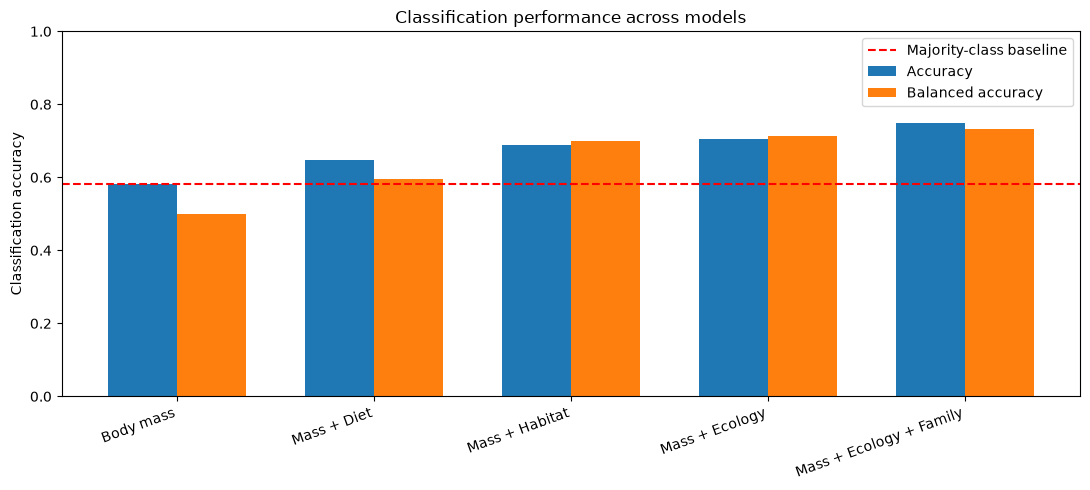

In [40]:
models = [
    "Body mass",
    "Mass + Diet",
    "Mass + Habitat",
    "Mass + Ecology",
    "Mass + Ecology + Family"
]

accuracy = [0.581, 0.647, 0.689, 0.705, 0.749]
balanced = [0.500, 0.596, 0.700, 0.712, 0.733]

x = np.arange(len(models))
width = 0.35

fig, ax = plt.subplots(figsize=(11, 5))

ax.bar(x - width/2, accuracy, width, label="Accuracy")
ax.bar(x + width/2, balanced, width, label="Balanced accuracy")

ax.axhline(
    0.581,
    color="red",
    linestyle="--",
    label="Majority-class baseline"
)

ax.set_xticks(x)
ax.set_xticklabels(models, rotation=20, ha="right")
ax.set_ylabel("Classification accuracy")
ax.set_ylim(0, 1)
ax.set_title("Classification performance across models")
ax.legend()

plt.tight_layout()
plt.show()

### Confusion matrices

Rows indicate actual classes and columns predicted classes. Model C improves overall accuracy, especially for warm-climate species, while Model B correctly identifies more cool-climate species. Higher overall accuracy does not imply improvement for every class.

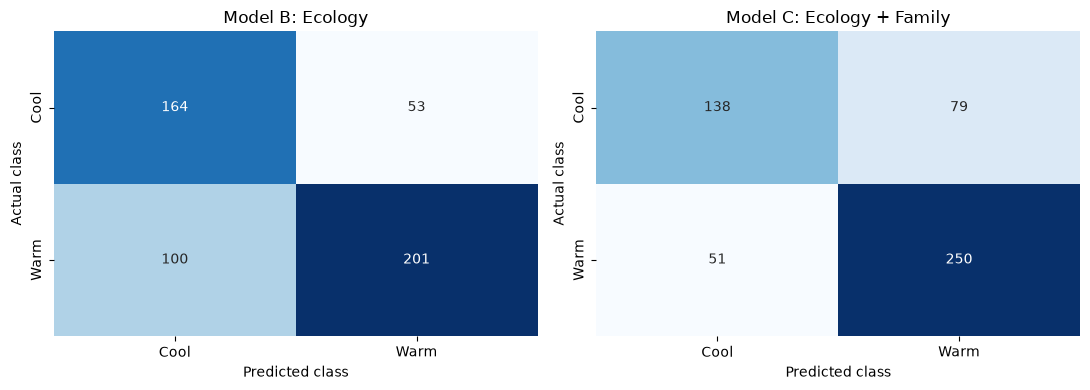

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, model, title in zip(
    axes,
    [model_b, model_c],
    ["Model B: Ecology", "Model C: Ecology + Family"]
):
    predictions = model.predict(
        test_df[[
            "LogBodyMass", "TrophicLevel", "HabitatOpenness"
        ] + (["Family"] if model is model_c else [])]
    )

    cm = confusion_matrix(
        test_df["WarmClimate"],
        predictions
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        xticklabels=["Cool", "Warm"],
        yticklabels=["Cool", "Warm"],
        ax=ax
    )

    ax.set_title(title)
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("Actual class")

plt.tight_layout()
plt.show()

### Habitat composition and overall conclusions

Habitat openness differs markedly between the cool and warm categories among species with recorded habitats. Open habitats are relatively more common in the cool group, while dense habitats are more common in the warm group. This is consistent with habitat being informative in the classifiers, but does not establish a causal explanation.

**Summary:** Across Rodentia, mean annual temperature is a very weak predictor of log body mass and the estimated slope is opposite to the prediction of Bergmann's rule. The relationship is more negative within Sciuridae but varies considerably by genus. Classification reinforces that body mass alone is not useful for distinguishing the chosen temperature categories; ecological and family information improve prediction.

**Limitations:** One observation per species, evolutionary non-independence, incomplete habitat records, some inferred body masses, heterogeneity within climate categories, an exploratory temperature threshold, and evaluation on a single random train/test split. These analyses establish associations, not causes. Because several additional models were examined on the same test set, small differences in their reported scores should be interpreted cautiously.

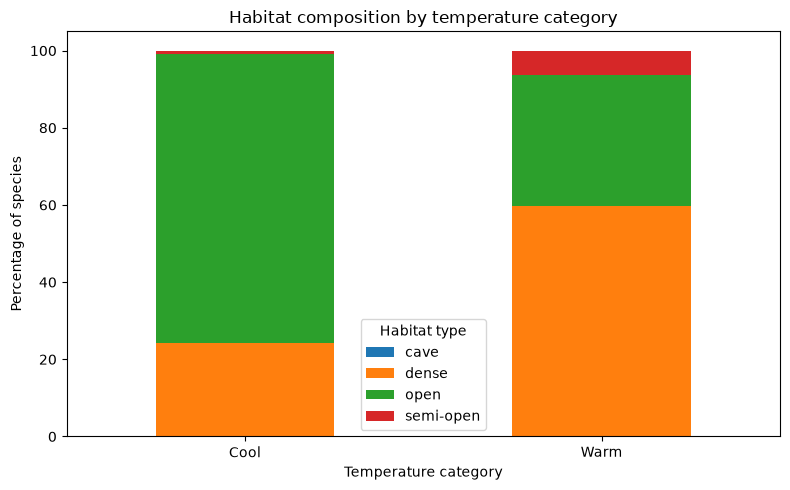

In [42]:
habitat_table.T.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5)
)

plt.title("Habitat composition by temperature category")
plt.xlabel("Temperature category")
plt.ylabel("Percentage of species")
plt.xticks(rotation=0)
plt.legend(title="Habitat type")
plt.tight_layout()
plt.show()